## Configuration

Use `FEATURE_EXTRACTORS_TO_RUN` to select `tfidf`, `glove`, or both. Use `MODELS_TO_RUN` to select Logistic Regression, linear SVM, or both. The trailing comma is required for a one-item tuple.

In [1]:
FEATURE_EXTRACTORS_TO_RUN = ('tfidf', 'glove')
MODELS_TO_RUN = ('logistic_regression', 'linear_svm')

## Setup

Locate the project whether the notebook is opened from the repository root or from `notebooks/`, then import the reusable pipeline components.

Public data sources used by this notebook:

- Dataset CSV files: [pinned Hugging Face revision](https://huggingface.co/datasets/ImpactTom6819/covid_tweets_practice/tree/5e441292c9120525a4ddd54eba3d65187d66bf49).
- Pretrained embeddings: [Gensim glove-twitter-100 archive](https://github.com/RaRe-Technologies/gensim-data/releases/download/glove-twitter-100/glove-twitter-100.gz).

In [2]:
from pathlib import Path
import sys

PROJECT_ROOT = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / 'modules').exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run this notebook from the extracted project folder.')
sys.path.insert(0, str(PROJECT_ROOT))

In [3]:
import subprocess
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-r',
    str(PROJECT_ROOT / 'requirements.txt'),
])

import importlib
import pandas as pd
import modules.plotter as plotter
plotter = importlib.reload(plotter)
from modules.data_downloader import load_dataset
from modules.data_preprocessor import prepare_data, save_preparation_audit
from modules.evaluator import evaluate_models, validate_models
from modules.feature_extractor import GloveFeatureExtractor, TfidfFeatureExtractor
from modules.models import LinearSVMModel, LogisticRegressionModel
from modules.text_eda import run_eda
from modules.trainer import (
    PreparedData,
    fit_final_models,
    load_precomputed_feature_representations,
    save_feature_representations,
    save_precomputed_feature_representations,
    tune_models,
)


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip


## 1. Exploratory data analysis

EDA uses the official training split. The test file is inspected only for schema and integrity checks.

Training shape: (41157, 6)
Test shape:     (3798, 6)
Columns: ['UserName', 'ScreenName', 'Location', 'TweetAt', 'OriginalTweet', 'Sentiment']

Training sample:
   TweetAt                                                                                                                                                                                                                                 OriginalTweet Sentiment
16-03-2020                                                                                                                               @MeNyrbie @Phil_Gahan @Chrisitv https://t.co/iFz9FAn2Pa and https://t.co/xX6ghGFzCC and https://t.co/I2NlzdxNo8   Neutral
16-03-2020 advice Talk to your neighbours family to exchange phone numbers create contact list with phone numbers of neighbours schools employer chemist GP set up online shopping accounts if poss adequate supplies of regular meds but not over order  Positive
16-03-2020                                                     

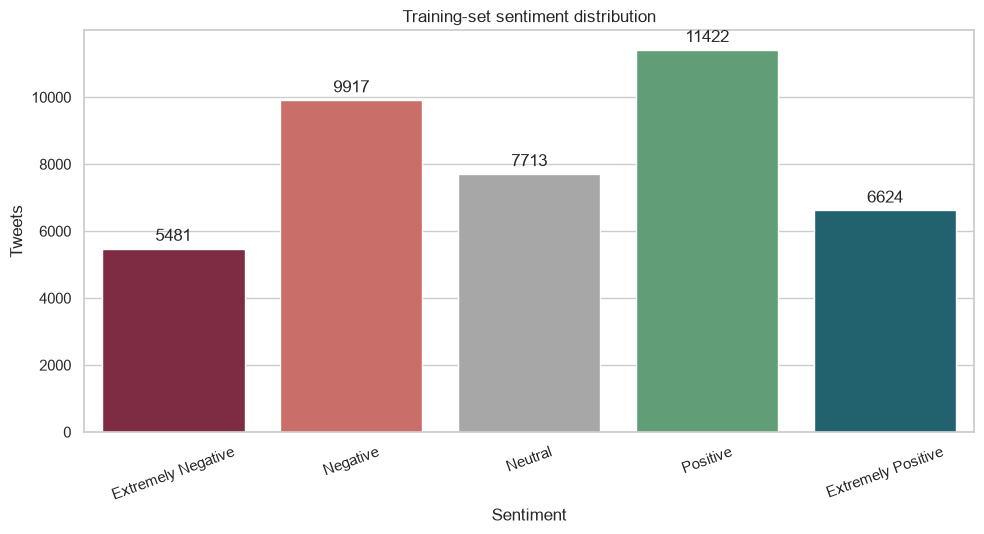

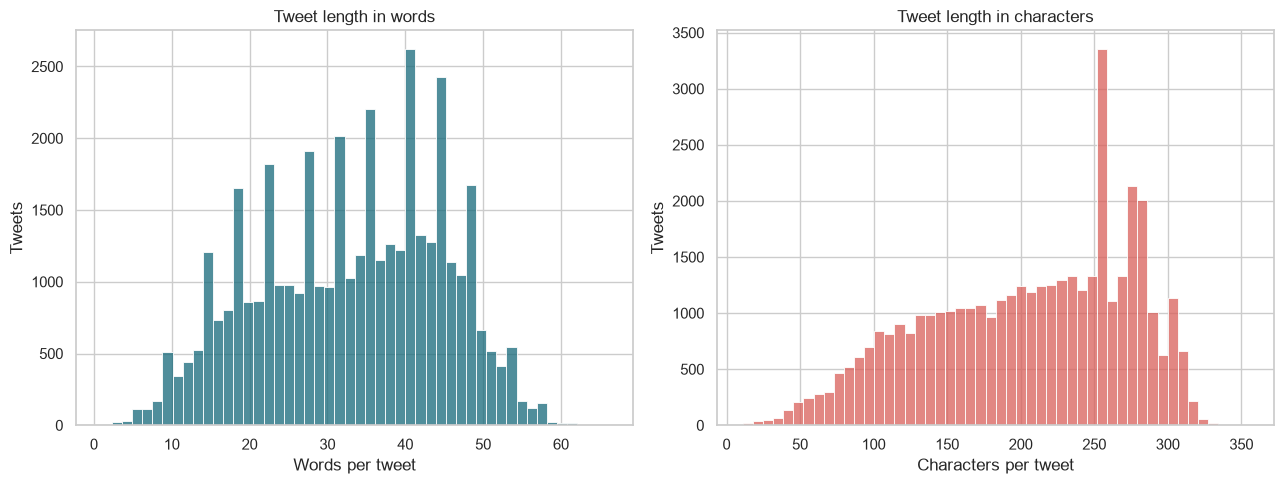

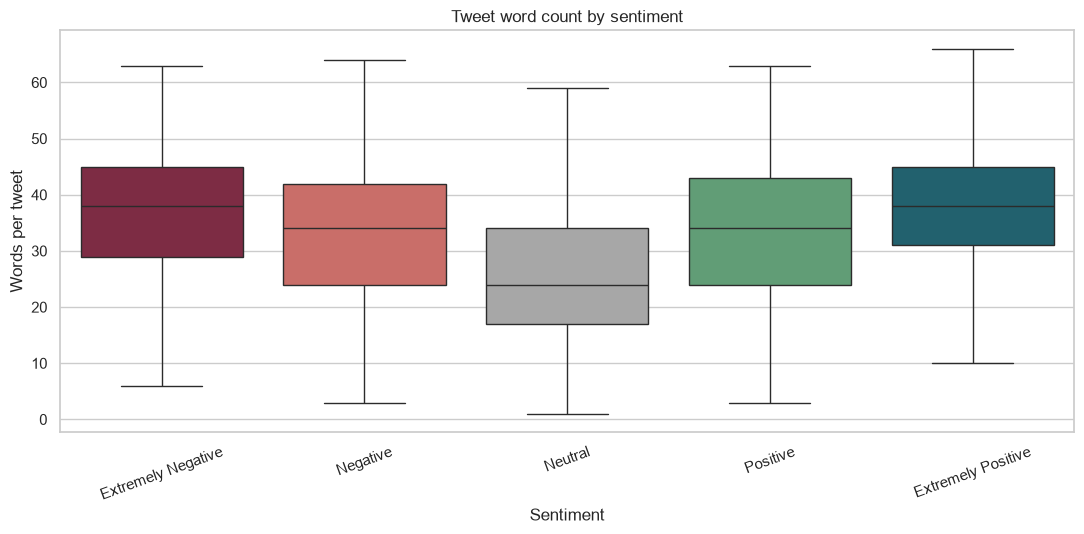

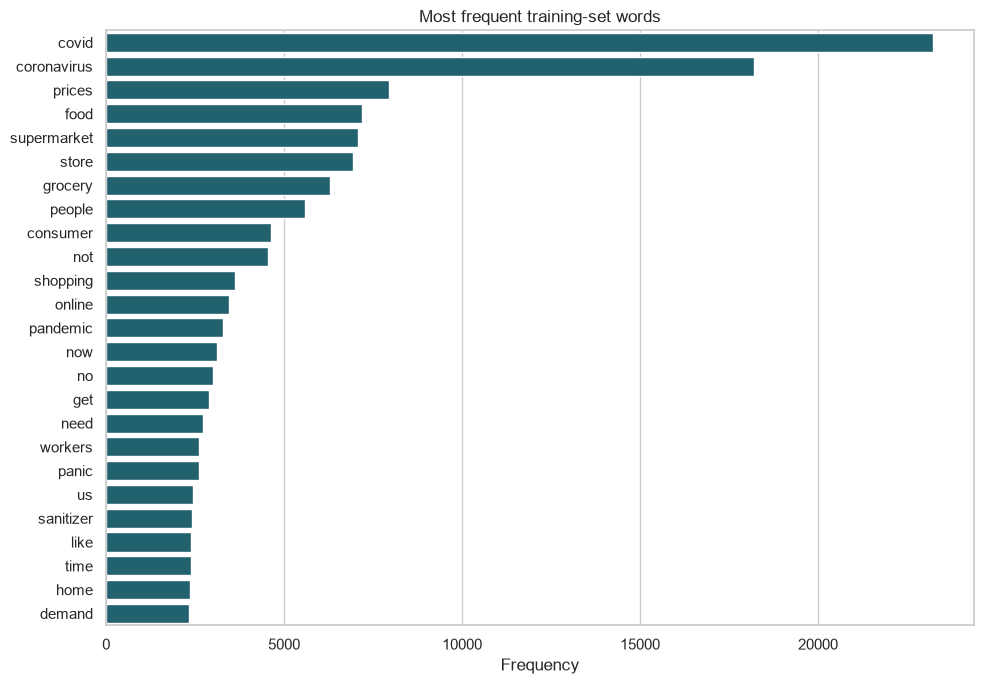

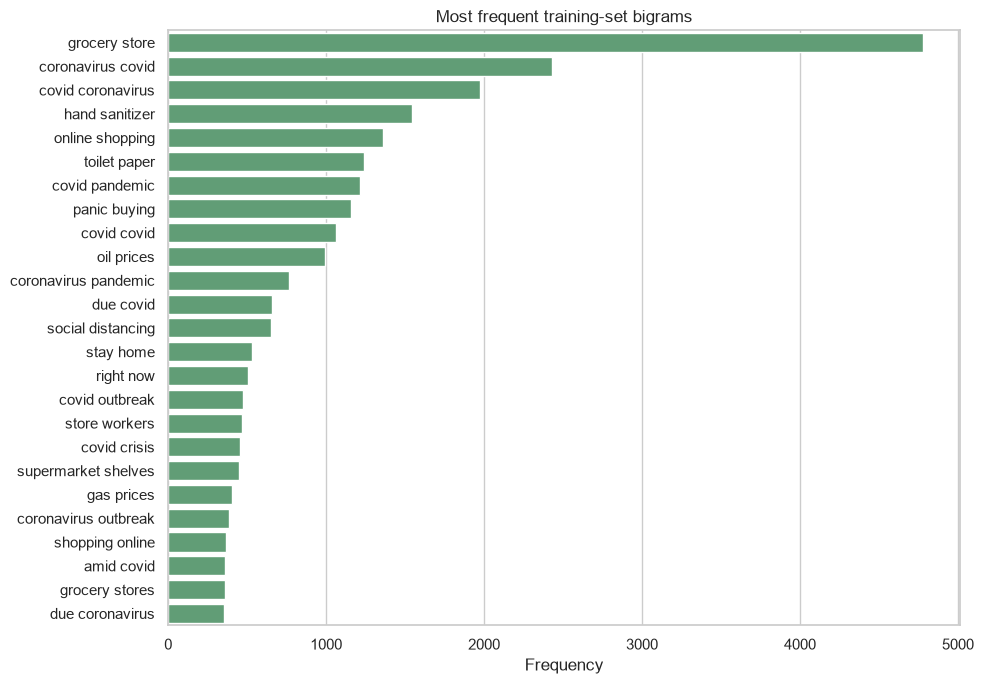


Saved figures to: /Users/minhtrinh/Downloads/Machine_Learning/machine-learning-large-assignment/outputs/graphics/eda
Saved two summary tables to: /Users/minhtrinh/Downloads/Machine_Learning/machine-learning-large-assignment/outputs/generated/eda


,split,rows,columns,missing_text,missing_sentiment,empty_or_whitespace_text,exact_duplicate_rows,duplicated_text_rows,duplicate_text_groups_with_conflicting_labels,unique_train_test_text_overlap
0,train,41157,6,0,0,0,0,28,0,1
1,test,3798,6,0,0,0,0,0,0,1


,sentiment,count,percentage
0,Extremely Negative,5481,13.317297
1,Negative,9917,24.095537
2,Neutral,7713,18.740433
3,Positive,11422,27.752266
4,Extremely Positive,6624,16.094468


In [4]:
eda = run_eda(PROJECT_ROOT)
display(eda['quality'])
display(eda['class_distribution'])

## 2. Prepare shared data

Remove duplicates and train/test overlap, normalize the text, and create one stratified train-validation split shared by every configured model.

In [5]:
train_raw, test_raw = load_dataset(PROJECT_ROOT / 'data')
train, validation, test, audit = prepare_data(train_raw, test_raw)
prepared_data = PreparedData(train, validation, test, audit)
save_preparation_audit(
    audit, PROJECT_ROOT / 'outputs/generated/preprocess/data_preparation_audit.json'
)
prepared_data.audit

{'raw_training_rows': 41157,
 'raw_test_rows': 3798,
 'overlapping_training_rows_removed': 1,
 'duplicate_training_rows_removed': 15,
 'clean_training_rows': 41141,
 'train_rows': 32912,
 'validation_rows': 8229,
 'test_rows': 3798}

## 3. Visualise extracted features before modelling

Fit visualization-only copies of the configured feature extractors on the clean training corpus, then display PCA/SVD, t-SNE, and UMAP projections. The same stratified 5,000-tweet sample is used for every plot. These reductions are diagnostic only: the classifiers below still receive the original TF-IDF and GloVe representations.

Loading pretrained embeddings: glove-twitter-100


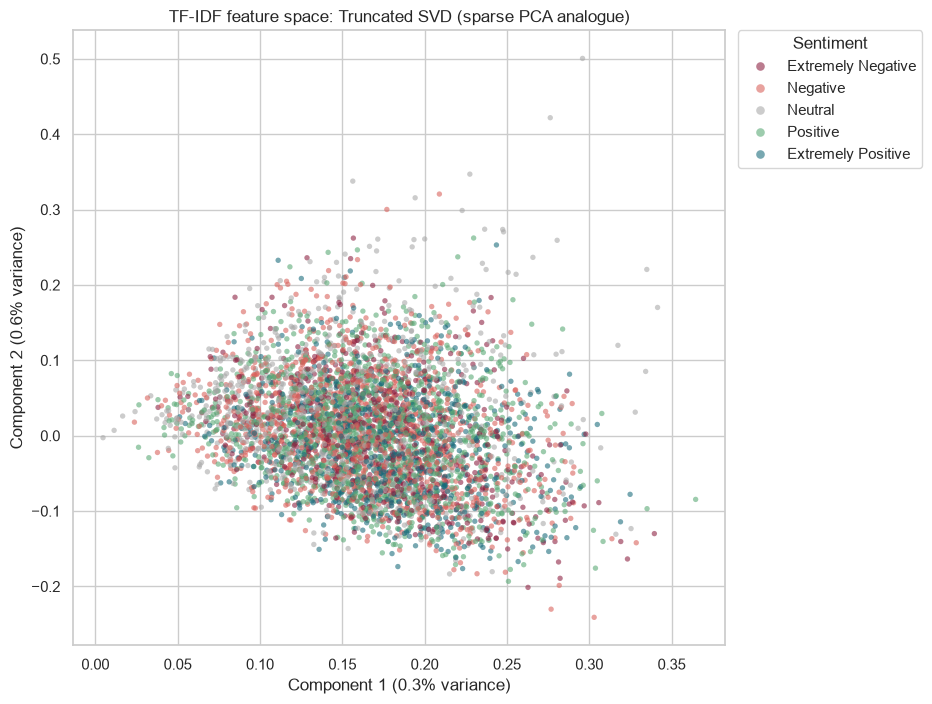

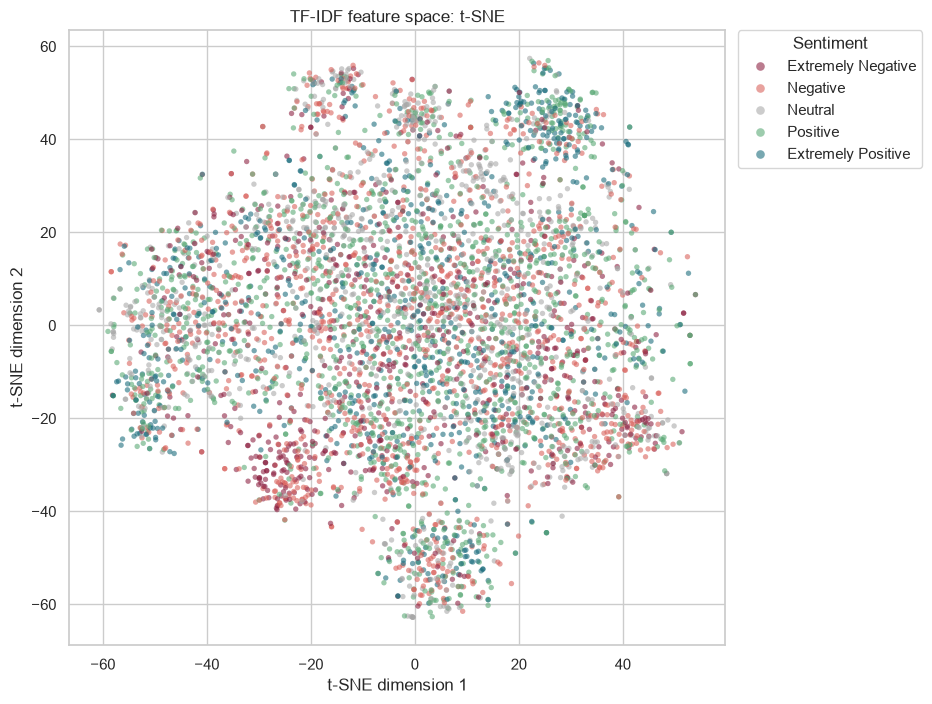

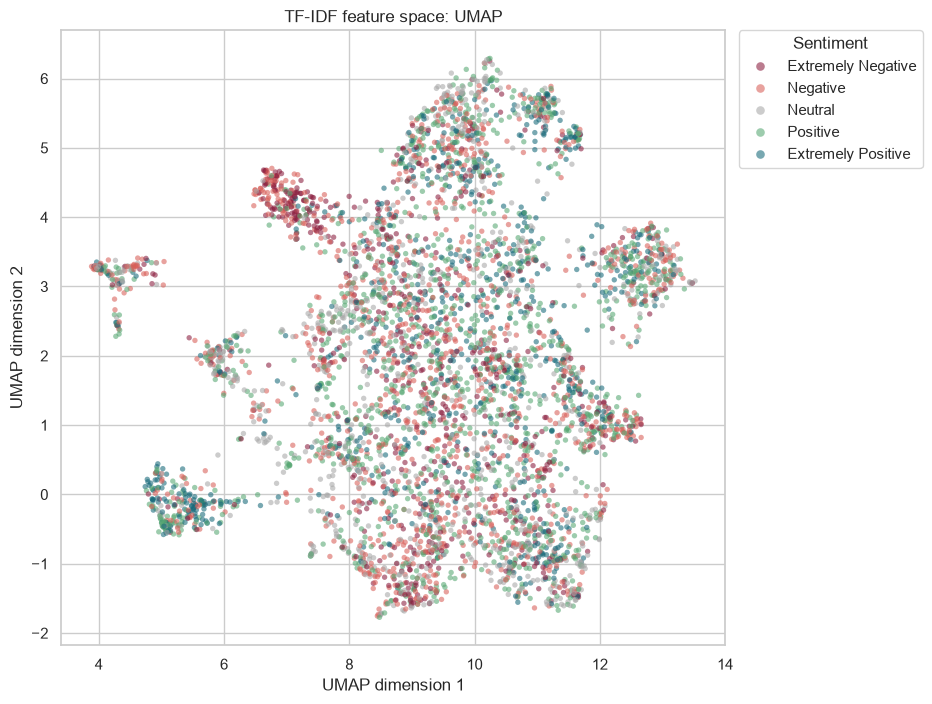

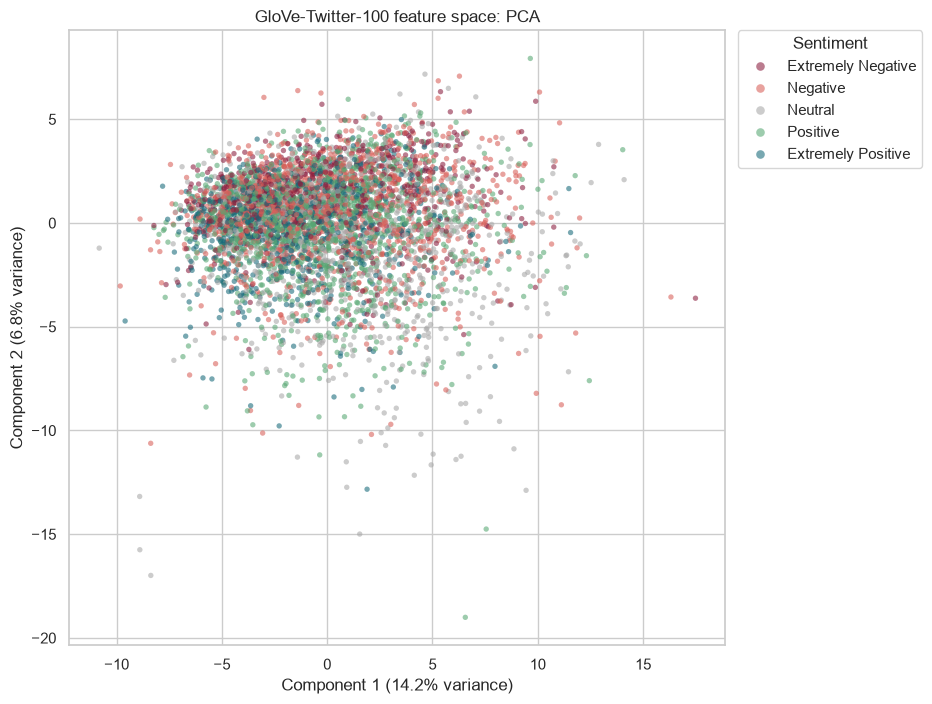

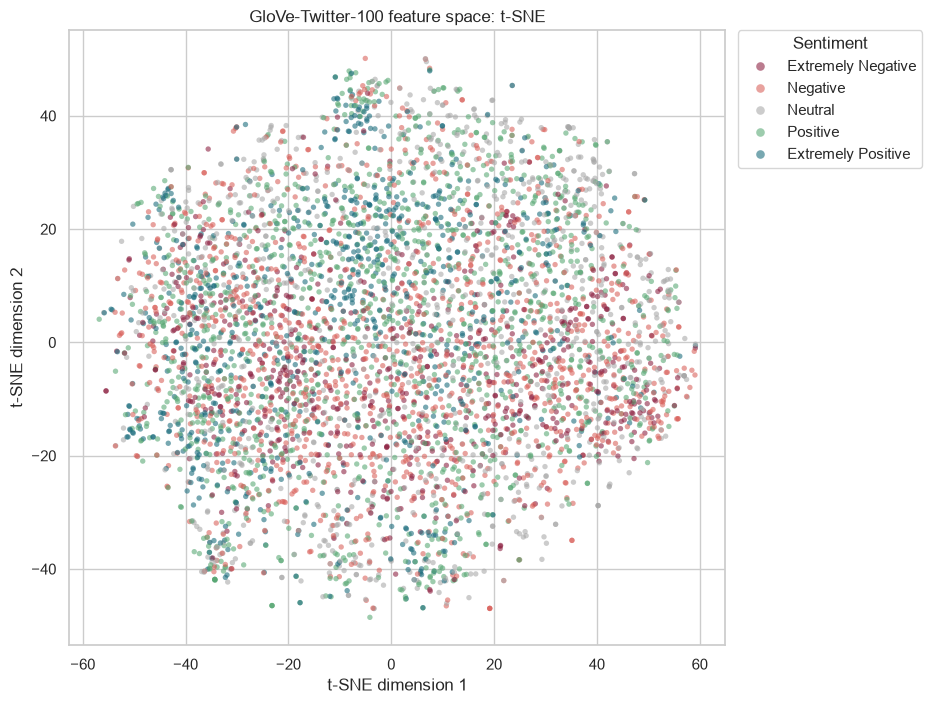

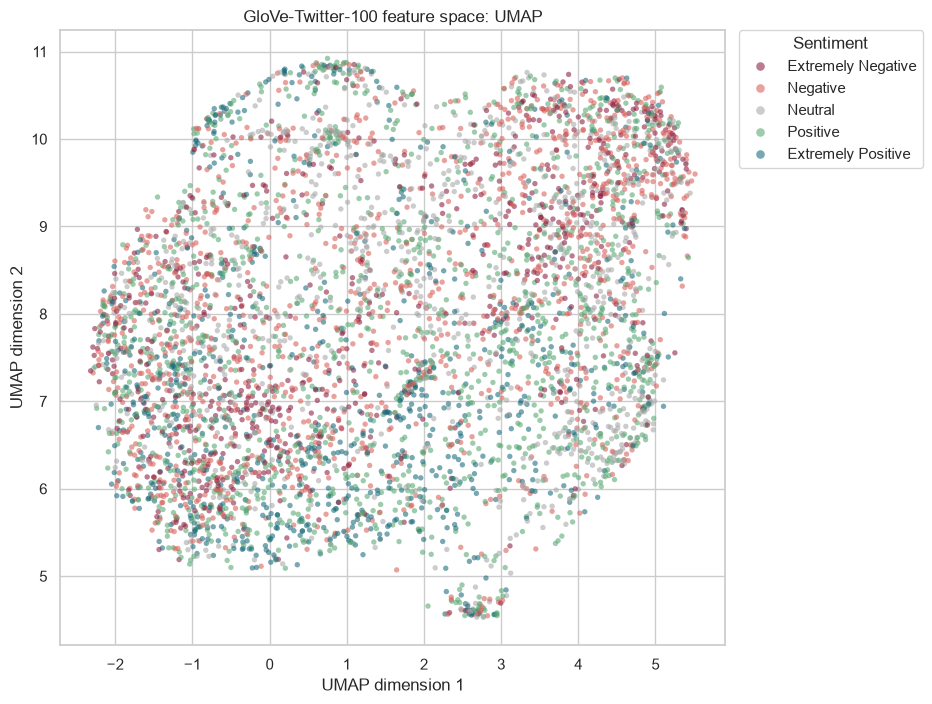

{'source_split': 'clean training set only',
 'sample_size': 5000,
 'sampling': 'class-stratified without replacement',
 'random_seed': 42,
 'shared_sample_across_representations': True,
 'tsne': {'perplexity': 30, 'max_iter': 1000, 'input_dimensions': 50},
 'umap': {'n_neighbors': 15,
  'min_dist': 0.1,
  'metric': 'cosine',
  'input_dimensions': 50},
 'representations': {'tfidf': {'feature_label': 'TF-IDF',
   'linear_method': 'Truncated SVD (sparse PCA analogue)',
   'component_1_explained_variance': 0.0026279292069375515,
   'component_2_explained_variance': 0.0058562494814395905,
   'first_50_components_explained_variance': 0.11723247915506363},
  'glove': {'feature_label': 'GloVe-Twitter-100',
   'linear_method': 'PCA',
   'component_1_explained_variance': 0.1421545296907425,
   'component_2_explained_variance': 0.06813504546880722,
   'first_50_components_explained_variance': 0.8732162714004517}}}

In [6]:
# Reload local plotting code so rerunning this cell in an existing kernel
# cannot use a stale function signature from before the notebook update.
import importlib
import modules.plotter as plotter
plotter = importlib.reload(plotter)

visualization_extractors = {
    'tfidf': TfidfFeatureExtractor(),
    'glove': GloveFeatureExtractor(PROJECT_ROOT),
}
unknown_features = set(FEATURE_EXTRACTORS_TO_RUN) - visualization_extractors.keys()
if unknown_features:
    raise ValueError(f'Unknown feature selection: {sorted(unknown_features)}')
visualization_representations = {}
full_train = prepared_data.full_train
for feature_name in FEATURE_EXTRACTORS_TO_RUN:
    extractor = visualization_extractors[feature_name]
    extractor.fit(full_train['ProcessedTweet'])
    visualization_representations[feature_name] = (
        extractor.transform(full_train['ProcessedTweet']),
        extractor.label,
    )

feature_space_metadata = plotter.plot_feature_space_visualizations(
    PROJECT_ROOT,
    representations=visualization_representations,
    labels=full_train['Sentiment'],
)
display(feature_space_metadata)

In [7]:
AVAILABLE_FEATURE_EXTRACTORS = {'tfidf', 'glove'}
MODEL_FACTORIES = {
    'logistic_regression': LogisticRegressionModel,
    'linear_svm': LinearSVMModel,
}
if not FEATURE_EXTRACTORS_TO_RUN or not MODELS_TO_RUN:
    raise ValueError('Select at least one feature extractor and one model')
unknown_features = set(FEATURE_EXTRACTORS_TO_RUN) - AVAILABLE_FEATURE_EXTRACTORS
if unknown_features:
    raise ValueError(f'Unknown feature selection: {sorted(unknown_features)}')
unknown_models = set(MODELS_TO_RUN) - MODEL_FACTORIES.keys()
if unknown_models:
    raise ValueError(f'Unknown model selection: {sorted(unknown_models)}')

def run_experiment(extractor):
    models = [MODEL_FACTORIES[name]() for name in MODELS_TO_RUN]
    if extractor.name == 'glove' and 'logistic_regression' in MODELS_TO_RUN:
        models[MODELS_TO_RUN.index('logistic_regression')] = LogisticRegressionModel((0.5, 1.0, 2.0))

    precomputed = None
    if extractor.name == 'glove':
        save_precomputed_feature_representations(
            extractor, prepared_data.train, prepared_data.validation,
            prepared_data.full_train, prepared_data.test, PROJECT_ROOT
        )
        precomputed = load_precomputed_feature_representations(
            extractor, PROJECT_ROOT
        )
        print('Reloaded saved GloVe .npy files as classifier inputs.')

    tuning = tune_models(
        extractor, models, prepared_data.train, PROJECT_ROOT,
        train_features=None if precomputed is None else precomputed['development'],
    )
    validation = validate_models(
        tuning, prepared_data.validation,
        validation_features=None if precomputed is None else precomputed['validation'],
    )
    training = fit_final_models(
        tuning, prepared_data.full_train, PROJECT_ROOT,
        full_train_features=None if precomputed is None else precomputed['train'],
    )
    if precomputed is None:
        save_feature_representations(
            training, prepared_data.full_train, prepared_data.test,
            validation.selected_model, PROJECT_ROOT
        )
    return evaluate_models(
        training, extractor, prepared_data.test, validation, PROJECT_ROOT,
        test_features=None if precomputed is None else precomputed['test'],
    )

## 4. Build, tune, and evaluate the models

### TF-IDF

Fit sparse word-level TF-IDF features and train only the classifiers selected above. Model pipelines use fresh extractor instances and the original high-dimensional representation, not the two-dimensional visualizations.

In [8]:
results = {}
if 'tfidf' in FEATURE_EXTRACTORS_TO_RUN:
    results['tfidf'] = run_experiment(TfidfFeatureExtractor())


Tuning logistic_regression on TF-IDF features ...
Fitting 3 folds for each of 8 candidates, totalling 24 fits

CV results for every TF-IDF + logistic_regression candidate (sorted by macro-F1 rank):
 candidate                                                                                     parameters mean_cv_macro_f1 std_cv_macro_f1 mean_cv_accuracy  rank_cv_macro_f1  selected
         3       {"feature_extractor__ngram_range": [1, 1], "model__C": 1.0, "model__class_weight": null}           0.5509          0.0034           0.5479                 1      True
         4 {"feature_extractor__ngram_range": [1, 1], "model__C": 1.0, "model__class_weight": "balanced"}           0.5497          0.0026           0.5421                 2     False
         8 {"feature_extractor__ngram_range": [1, 2], "model__C": 1.0, "model__class_weight": "balanced"}           0.5310          0.0023           0.5228                 3     False
         1       {"feature_extractor__ngram_range": [1, 1], "mode

### GloVe-Twitter-100

Mean-pool pretrained Twitter embeddings and save the development, validation, complete-training, and test matrices as `.npy` files before model training. The notebook reloads those files and uses the reloaded arrays as the direct inputs to cross-validation, final fitting, validation, and test evaluation. The first run downloads the vectors into the project cache.

In [9]:
if 'glove' in FEATURE_EXTRACTORS_TO_RUN:
    results['glove'] = run_experiment(GloveFeatureExtractor(PROJECT_ROOT))

Reloaded saved GloVe .npy files as classifier inputs.

Tuning logistic_regression on GloVe-Twitter-100 features ...
Fitting 3 folds for each of 6 candidates, totalling 18 fits

CV results for every GloVe-Twitter-100 + logistic_regression candidate (sorted by macro-F1 rank):
 candidate                                           parameters mean_cv_macro_f1 std_cv_macro_f1 mean_cv_accuracy  rank_cv_macro_f1  selected
         1       {"model__C": 0.5, "model__class_weight": null}           0.4406          0.0048           0.4384                 1      True
         5       {"model__C": 2.0, "model__class_weight": null}           0.4405          0.0044           0.4383                 2     False
         3       {"model__C": 1.0, "model__class_weight": null}           0.4405          0.0046           0.4384                 3     False
         4 {"model__C": 1.0, "model__class_weight": "balanced"}           0.4157          0.0019           0.4130                 4     False
         2 {"mo

## 5. Results

Display each feature-model metric table and confusion matrix, then create the consolidated four-combination comparison exactly once.

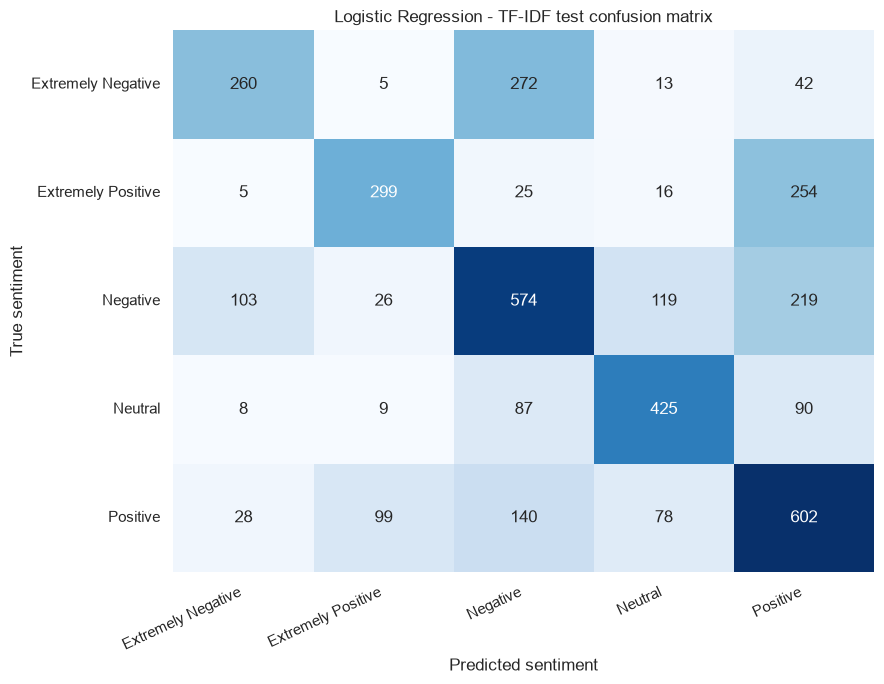

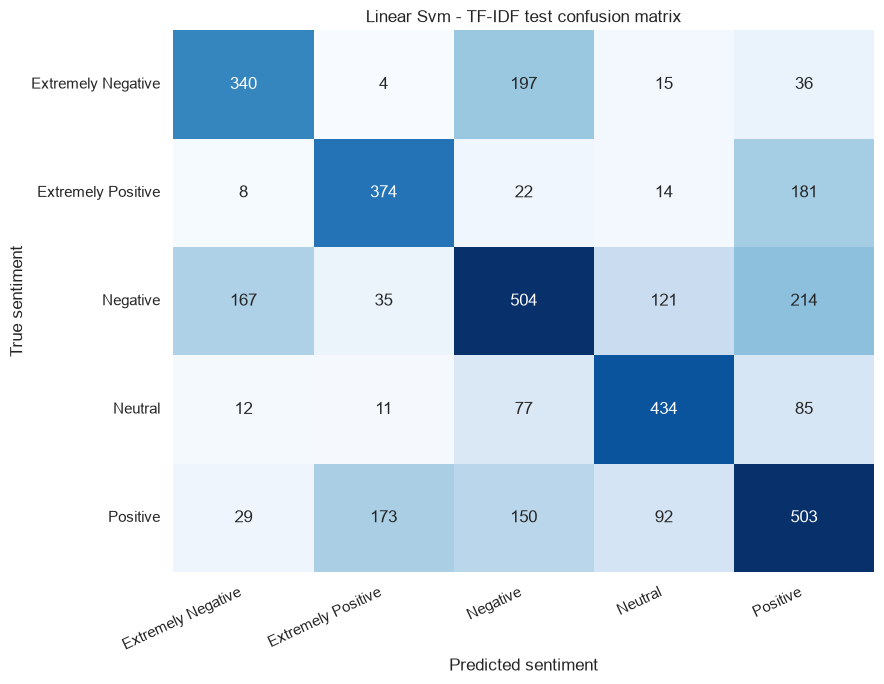

TF-IDF selected: linear_svm


,feature_method,model,accuracy,macro_f1
0,TF-IDF,logistic_regression,0.568720,0.572741
1,TF-IDF,linear_svm,0.567404,0.581200


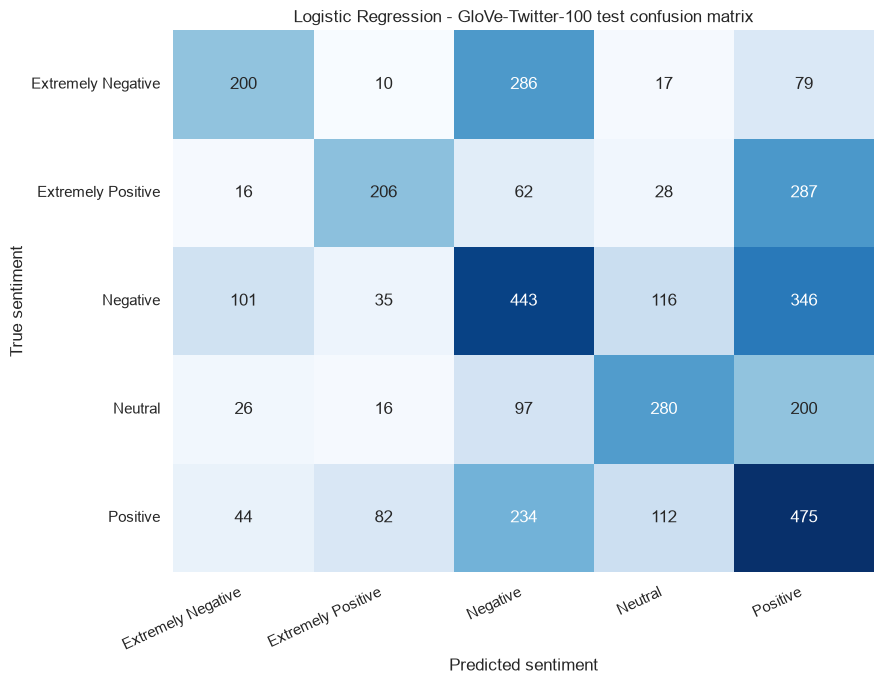

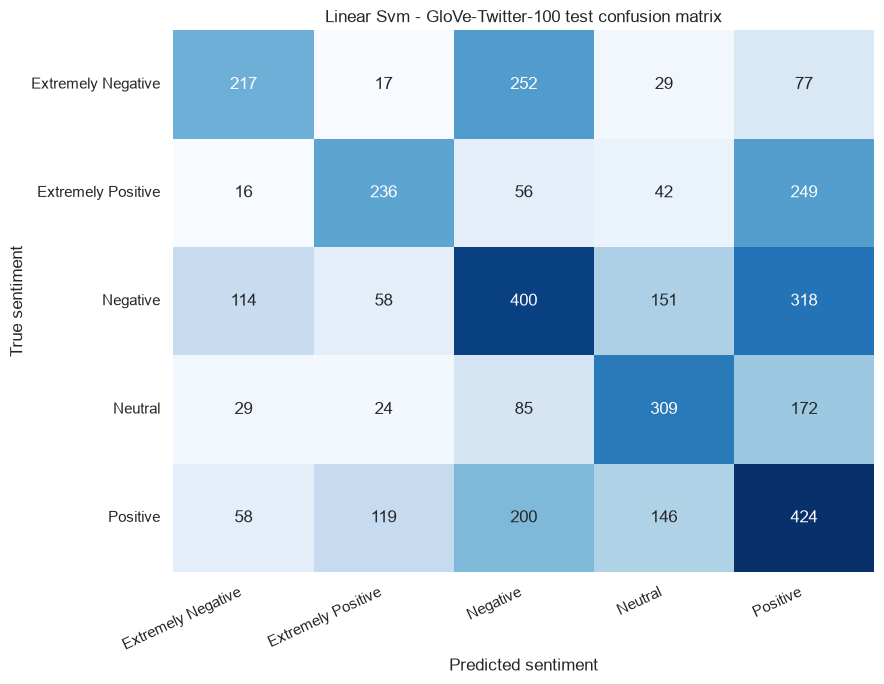

GloVe-Twitter-100 selected: logistic_regression


,feature_method,model,accuracy,macro_f1
0,GloVe-Twitter-100,logistic_regression,0.422328,0.427528
1,GloVe-Twitter-100,linear_svm,0.417588,0.425831


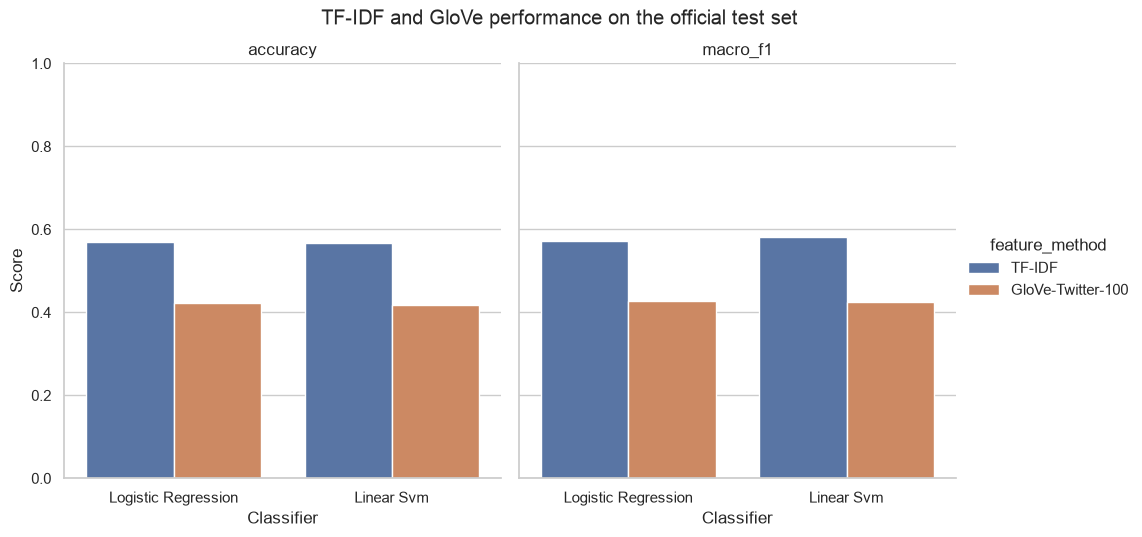

In [10]:
for feature_name, result in results.items():
    plotter.plot_experiment_results(
        result, prepared_data.test['Sentiment'], PROJECT_ROOT
    )
    print(f"{result['feature_label']} selected: {result['selected_model']}")
    display(result['test_metrics'])

combined_test_metrics = pd.concat(
    [result['test_metrics'] for result in results.values()],
    ignore_index=True,
)
plotter.plot_model_comparison(
    combined_test_metrics,
    PROJECT_ROOT / 'outputs/graphics/comparison/feature_model_comparison.png',
)

## Generated artifacts

The preceding cells save all reproducibility artifacts under the project-level `features/` and `outputs/` folders.

In [11]:
print('Feature matrices:', PROJECT_ROOT / 'features')
print('Figures and metrics:', PROJECT_ROOT / 'outputs')
print('Final report sources:', PROJECT_ROOT / 'report')

Feature matrices: /Users/minhtrinh/Downloads/Machine_Learning/machine-learning-large-assignment/features
Figures and metrics: /Users/minhtrinh/Downloads/Machine_Learning/machine-learning-large-assignment/outputs
Final report sources: /Users/minhtrinh/Downloads/Machine_Learning/machine-learning-large-assignment/report


### Saved files

Feature representations, aligned labels, and metadata are saved in the project-level `features/` folder.  

Other generated artifacts are grouped under `outputs/`:
  
figures in `outputs/graphics/`, 

metrics and audits in `outputs/generated/`

fitted pipelines in `outputs/models/`.